In [5]:
#import libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_csv("/content/student_dataset_10000_rows.csv")

In [7]:
df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


In [8]:
df.tail()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
9995,2,58,9,7,8,88,69.31,Not Placed
9996,7,98,6,9,4,87,100.00,Placed
9997,10,44,8,5,10,37,95.94,Placed
9998,10,75,7,5,8,52,88.61,Placed
9999,2,70,6,11,16,52,78.96,Placed


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  object 
dtypes: float64(1), int64(6), object(1)
memory usage: 625.1+ KB


In [10]:
df.describe()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,5.989600,69.88460,6.498500,6.062600,9.988400,64.91100,86.704207
std,3.163589,17.61653,1.709354,3.138163,6.034145,17.50302,15.058383
min,1.000000,40.00000,4.000000,1.000000,0.000000,35.00000,26.670000
25%,3.000000,55.00000,5.000000,3.000000,5.000000,50.00000,76.727500
50%,6.000000,70.00000,6.500000,6.000000,10.000000,65.00000,92.120000
75%,9.000000,85.00000,8.000000,9.000000,15.000000,80.00000,100.000000
max,11.000000,100.00000,9.000000,11.000000,20.000000,95.00000,100.000000


In [11]:
df.isnull().sum()

,0
study_hours,0
attendance,0
sleep_hours,0
internet_usage,0
assignments_completed,0
previous_score,0
exam_score,0
placement_status,0


In [12]:
df.duplicated().sum()

np.int64(0)

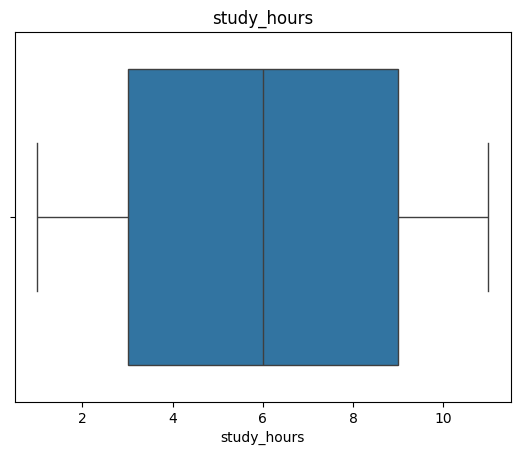

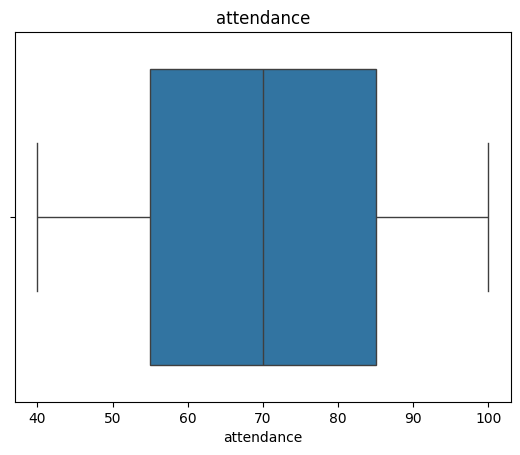

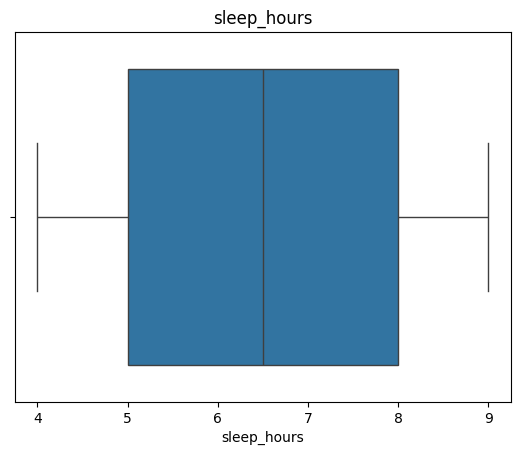

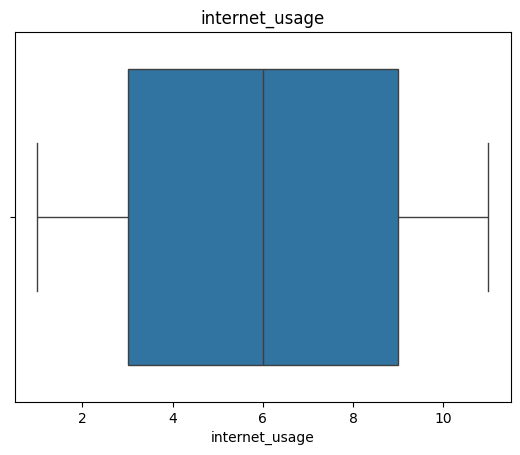

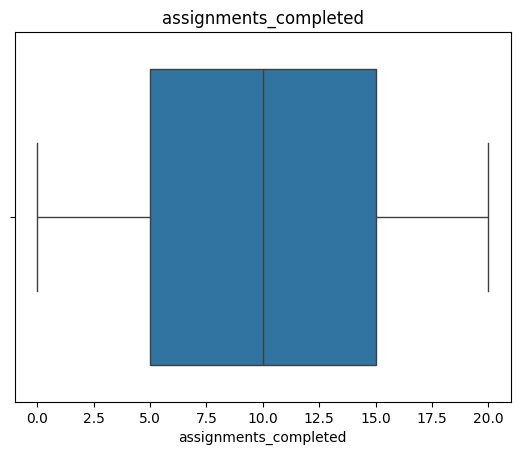

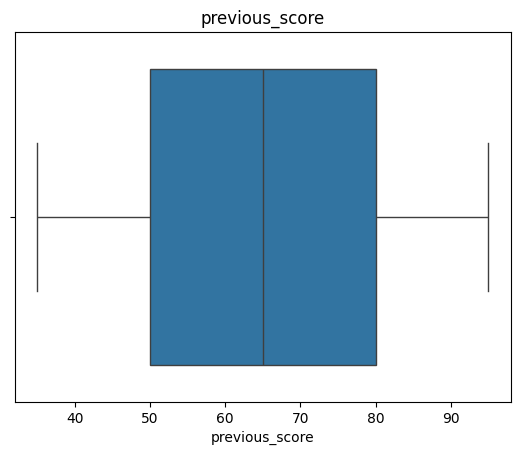

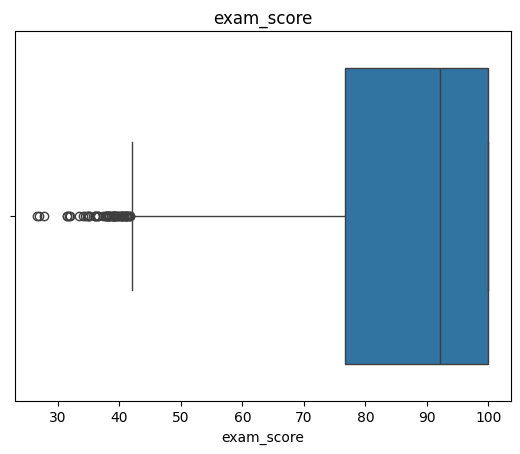

In [13]:
for col in df.select_dtypes(include = 'number').columns:

  sns.boxplot(x = df[col])

  plt.title(col)

  plt.show()


In [14]:
#Outlier treatment

Q1 = df['exam_score'].quantile(0.25)

Q2 = df['exam_score'].quantile(0.50)

Q3 = df['exam_score'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

df['exam_score'] = df['exam_score'].clip(lower_bound, upper_bound)

In [15]:
df = pd.get_dummies(df, columns=['placement_status'], drop_first=True, dtype=int)

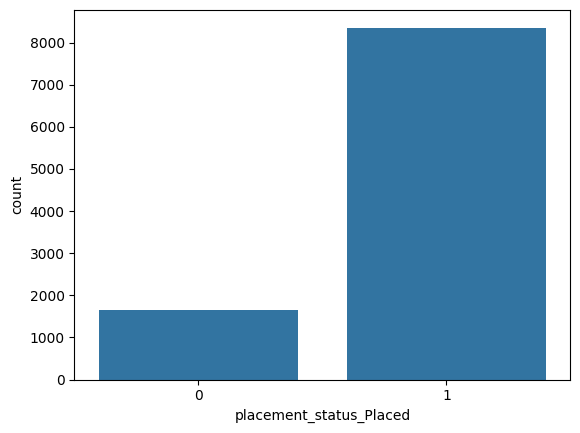

In [16]:
#univareant analysis
sns.countplot(x=df['placement_status_Placed'])
plt.show()

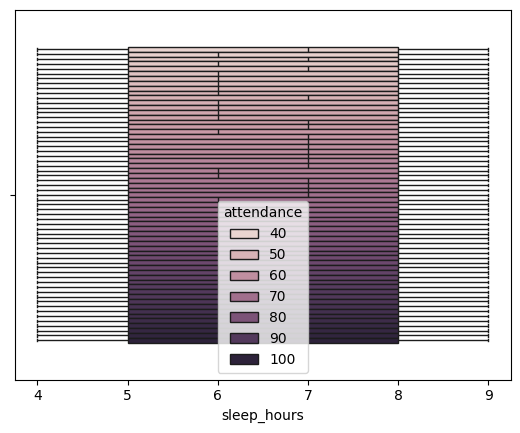

In [17]:
#bivareant analysis
df.columns = df.columns.str.strip()
sns.boxplot(x=df['sleep_hours'], hue=df['attendance'])
plt.show()

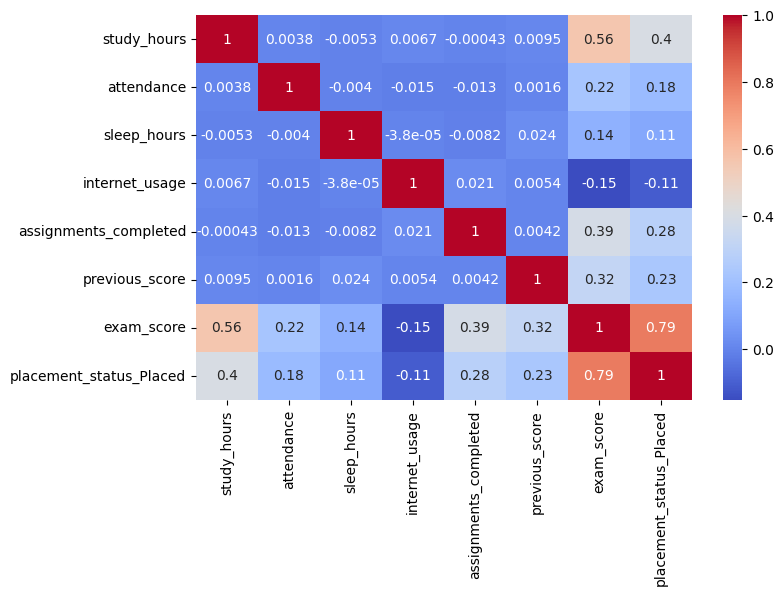

In [18]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only = True), annot = True,cmap = 'coolwarm')
plt.show()

In [19]:
df.select_dtypes(include='object').columns

Index([], dtype='object')

In [20]:
df.columns =df.columns.str.strip()
for col in df.select_dtypes(include='object').columns:
     df[col]=df[col].str.strip()

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   study_hours              10000 non-null  int64  
 1   attendance               10000 non-null  int64  
 2   sleep_hours              10000 non-null  int64  
 3   internet_usage           10000 non-null  int64  
 4   assignments_completed    10000 non-null  int64  
 5   previous_score           10000 non-null  int64  
 6   exam_score               10000 non-null  float64
 7   placement_status_Placed  10000 non-null  int64  
dtypes: float64(1), int64(7)
memory usage: 625.1 KB


In [24]:
#divide the data set in to x andy variables
x=df.drop(columns=['placement_status_Placed'])
y=df['placement_status_Placed']


In [25]:
#train_test
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [26]:
#model
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier()
model.fit(x_train,y_train)

RandomForestClassifier()

In [27]:
y_pred = model.predict(x_test)
print(y_pred)

[1 1 1 ... 1 1 0]


In [28]:
result=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
result.head(10)

,Actual,Predicted
6252,1,1
4684,1,1
1731,1,1
4742,1,1
4521,1,1
6340,1,1
576,1,1
5202,1,1
6363,1,1
439,1,1


In [29]:
from sklearn.metrics import accuracy_score
print("Accuracy :", accuracy_score(y_test,y_pred))

Accuracy : 0.9995


In [30]:
train_accuracy = model.score(x_train, y_train)
test_accuracy = model.score(x_test, y_test)
print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Train Accuracy: 1.0
Test Accuracy: 0.9995


In [31]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[ 344    1]
 [   0 1655]]


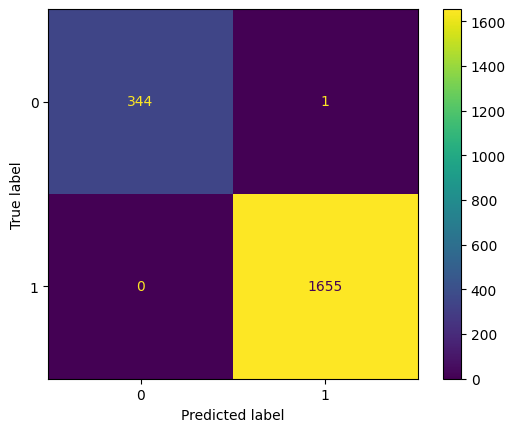

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [33]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       345
           1       1.00      1.00      1.00      1655

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [34]:
#hyper parameter tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10,20,30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(estimator=RandomForestClassifier(), param_grid=param_grid, cv=5,n_jobs=-1,verbose=1)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]},
             verbose=1)

In [35]:
print (grid_search.best_params_)
print (grid_search.best_score_)

{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
1.0


In [38]:
best_model = grid_search.best_estimator_
print("training accuracy:", best_model.score(x_train, y_train))
print("testing accuracy:", best_model.score(x_test, y_test))

training accuracy: 1.0
testing accuracy: 1.0


In [40]:
print("before tuning", model.score(x_test, y_test))
print("after tuning", best_model.score(x_test, y_test))

before tuning 0.9995
after tuning 1.0
